In [1]:
library('tidymodels')
library('palmerpenguins')
library('vip')

theme_set(theme_gray(base_size = 16))

── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Search for functions across packages at https://www.tidymodels.org/find/

Attaching package: ‘palmerpenguins’

The following object is masked from ‘package:modeldata’:

    penguins

The following objects are masked from ‘package:datasets’:

  

In [2]:
penguins2 = penguins |>
    drop_na()

penguins2 |> head()

  species island    bill_length_mm bill_depth_mm flipper_length_mm body_mass_g
1 Adelie  Torgersen 39.1           18.7          181               3750       
2 Adelie  Torgersen 39.5           17.4          186               3800       
3 Adelie  Torgersen 40.3           18.0          195               3250       
4 Adelie  Torgersen 36.7           19.3          193               3450       
5 Adelie  Torgersen 39.3           20.6          190               3650       
6 Adelie  Torgersen 38.9           17.8          181               3625       
  sex    year
1 male   2007
2 female 2007
3 female 2007
4 female 2007
5 male   2007
6 female 2007

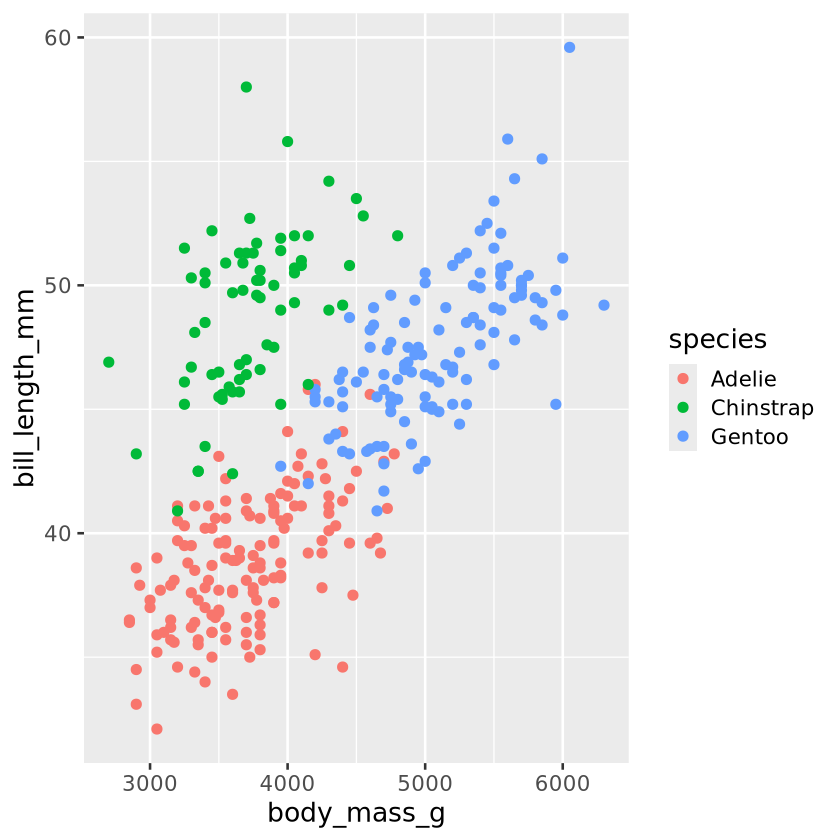

In [5]:
ggplot(penguins2, aes(x = body_mass_g, y = bill_length_mm, color = species)) + geom_point()

## Use random forests to model `bill_length_mm`

In [7]:
penguins2 |> names()

[1] "species"           "island"            "bill_length_mm"   
[4] "bill_depth_mm"     "flipper_length_mm" "body_mass_g"      
[7] "sex"               "year"             

In [8]:
mod = rand_forest() |> 
    set_engine('ranger', importance = 'impurity') |>
    set_mode('regression')

In [9]:
rec = recipe(bill_length_mm ~ ., data = penguins2) |>
    step_rm(year) |>
    step_dummy(sex, island, species) |>
    prep(retain = TRUE)

rec |> juice() |> head()

  bill_depth_mm flipper_length_mm body_mass_g bill_length_mm sex_male
1 18.7          181               3750        39.1           1       
2 17.4          186               3800        39.5           0       
3 18.0          195               3250        40.3           0       
4 19.3          193               3450        36.7           0       
5 20.6          190               3650        39.3           1       
6 17.8          181               3625        38.9           0       
  island_Dream island_Torgersen species_Chinstrap species_Gentoo
1 0            1                0                 0             
2 0            1                0                 0             
3 0            1                0                 0             
4 0            1                0                 0             
5 0            1                0                 0             
6 0            1                0                 0             

In [10]:
wf = workflow() |> 
  add_recipe(rec) |> 
  add_model(mod)

wf_fit = wf |> fit(data = penguins2)

wf_fit

ERROR: 

In [11]:
outcomes = augment(wf_fit |> extract_fit_parsnip(), 
                   new_data = rec |> juice())

outcomes |> head()

ERROR: object 'wf_fit' not found

In [15]:
options(repr.plot.width = 6, repr.plot.height = 5)

ggplot(outcomes) +
    geom_point(aes(x = bill_depth_mm, y = bill_length_mm)) + 
    geom_point(aes(x = bill_depth_mm, y = .pred), color = 'steelblue', size = 3,
               alpha = 0.5) +
    geom_segment(aes(x = bill_depth_mm, xend = bill_depth_mm, y = .pred, yend = bill_length_mm), 
                 color = 'firebrick',
                 alpha = 0.25)

ERROR: object 'outcomes' not found

## Visualize feature importance

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4)

wf_fit |> 
  extract_fit_parsnip() |> 
  vip()